In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6,3)

In [8]:
def plot_data(df, x, y, title, x_label, y_label):
    fig, ax = plt.subplots()
    for key, grp in df.groupby(['optimizer']):
        ax = grp.plot(ax=ax, kind='line', x=x, y=y, label=key[0])
    ax.set_title(title, fontdict={'fontweight':'bold'})
    ax.set_xlabel(xlabel=x_label)
    ax.xaxis.get_label().set_fontstyle('italic')
    ax.yaxis.get_label().set_fontstyle('italic')
    ax.set_ylabel(ylabel=y_label)
    ax.grid(visible=True)
    plt.legend(loc='best')    
    plt.show()


In [9]:
df = pd.read_csv('results-final.csv')
df

,n_features,n_targets,n_samples,test_size,optimizer,iterations,training_time,prediction_time,r2,mae,mse,rmse
0,3,2,100,40,cobyla,100,65.750599,0.412188,0.552594,0.098992,0.017047,0.130564
1,3,2,100,30,cobyla,100,75.980433,0.312961,0.638763,0.096882,0.015234,0.123425
2,3,2,100,20,cobyla,100,86.694838,0.193876,0.258306,0.178407,0.050046,0.223709
3,3,2,100,40,cobyla,300,196.158791,0.419283,0.848994,0.058484,0.005677,0.075348
4,3,2,100,30,cobyla,300,228.652219,0.317724,0.733825,0.079615,0.010958,0.104681
...,...,...,...,...,...,...,...,...,...,...,...,...
103,3,2,1000,30,slsqp,500,5817.449950,0.316276,0.870943,0.071518,0.008495,0.092168
104,3,2,1000,40,slsqp,500,5748.510787,0.409902,0.875976,0.070711,0.007846,0.088577
105,3,2,1000,30,adam,500,79632.939220,0.329169,0.005803,0.207032,0.065814,0.256542
106,3,2,1000,20,adam,500,80451.853440,0.189900,-0.349519,0.264793,0.095801,0.309517


In [10]:
df['training_time'] = df['training_time'].divide(3600)
df.sort_values(['r2'], ascending=False)

,n_features,n_targets,n_samples,test_size,optimizer,iterations,training_time,prediction_time,r2,mae,mse,rmse
69,3,2,500,30,lbfgsb,500,3.038106,0.331743,0.950387,0.037675,0.002900,0.053856
62,3,2,500,30,lbfgsb,300,3.423162,0.305992,0.950129,0.037786,0.002915,0.053995
46,3,2,500,30,lbfgsb,100,2.465552,0.305848,0.946087,0.039847,0.003146,0.056090
76,3,2,500,30,slsqp,500,0.793350,0.311405,0.941456,0.043764,0.003439,0.058639
74,3,2,500,30,slsqp,300,0.899132,0.303655,0.940731,0.041820,0.003455,0.058781
...,...,...,...,...,...,...,...,...,...,...,...,...
66,3,2,1000,20,adam,100,4.434632,0.195680,-3.871697,0.469816,0.323112,0.568430
22,3,2,100,20,adam,100,0.364940,0.206470,-4.383191,0.474170,0.379243,0.615827
68,3,2,1000,40,adam,100,4.362121,0.391905,-5.796295,0.543271,0.432110,0.657351
65,3,2,1000,30,adam,100,4.389648,0.291575,-8.441656,0.712560,0.626724,0.791659


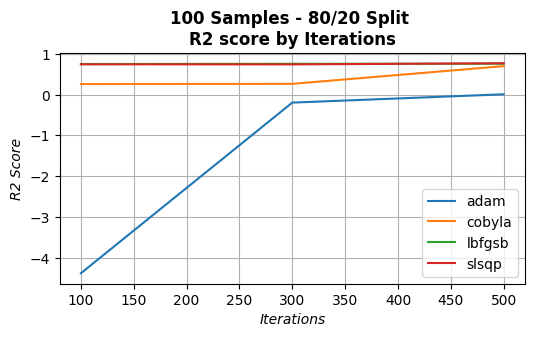

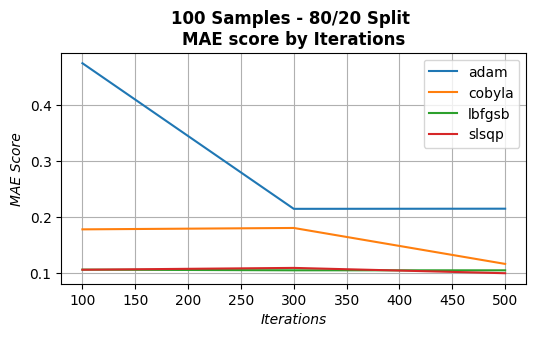

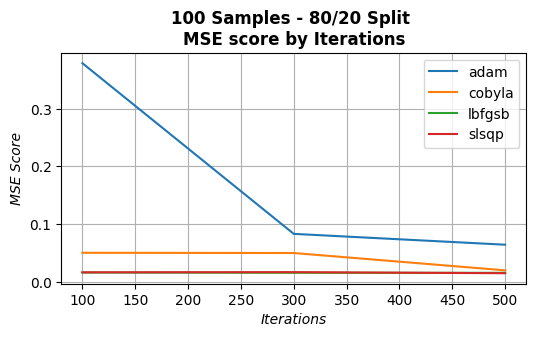

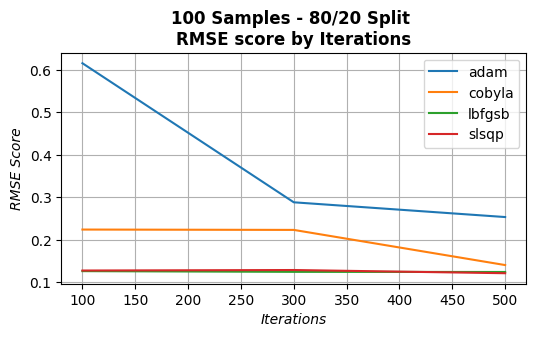

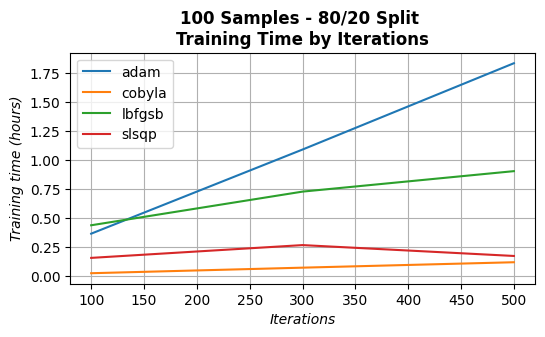

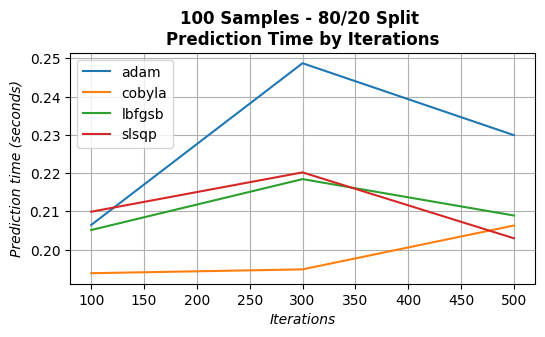

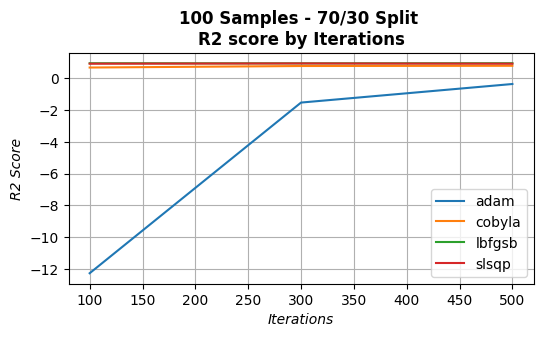

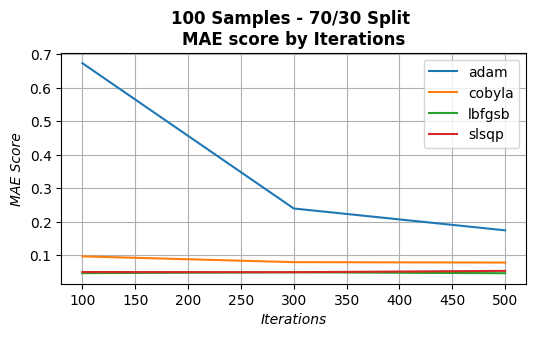

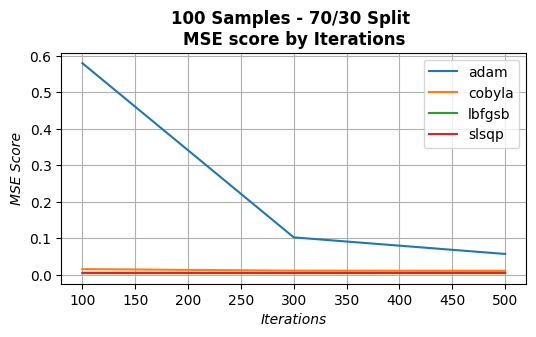

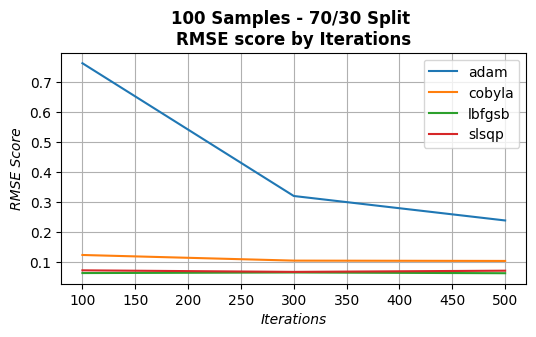

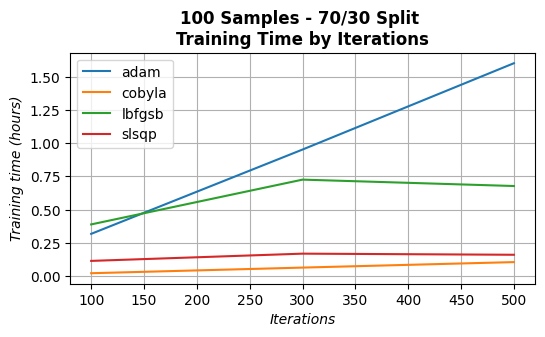

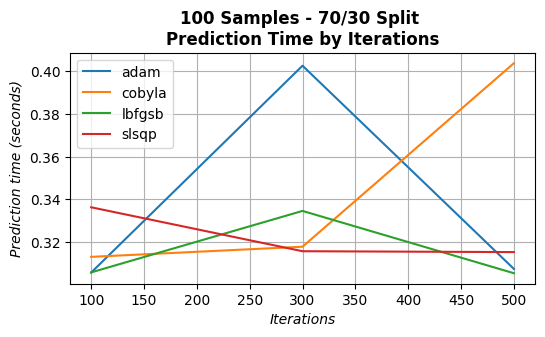

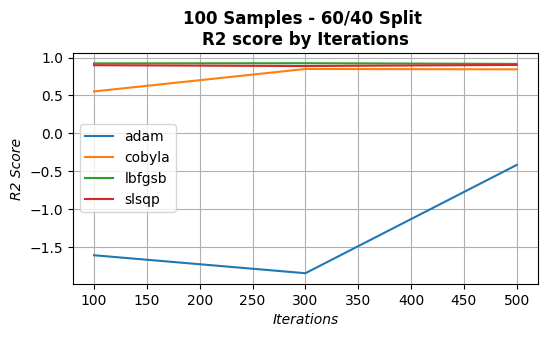

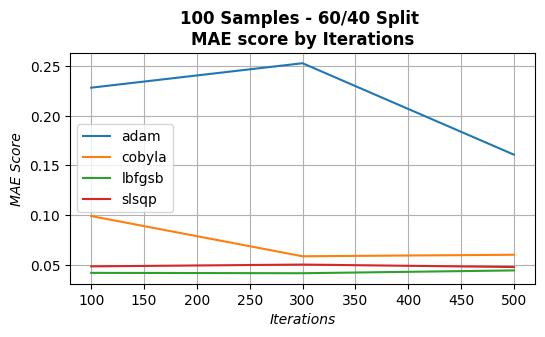

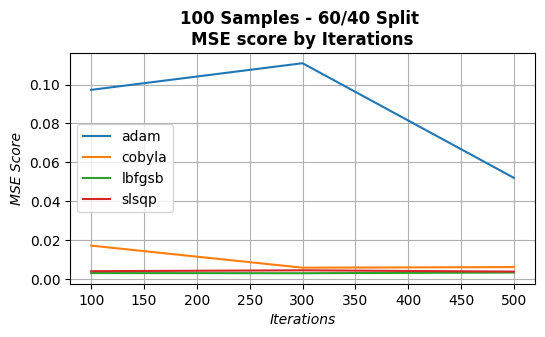

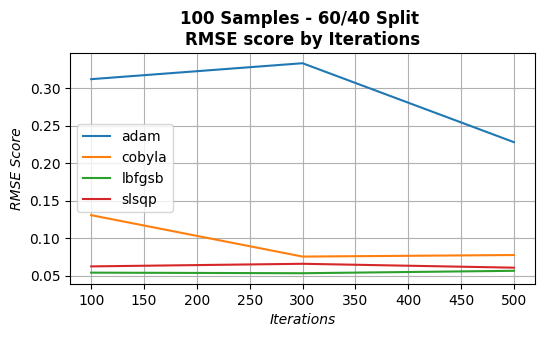

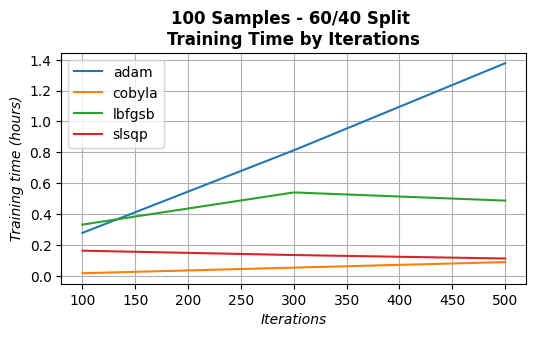

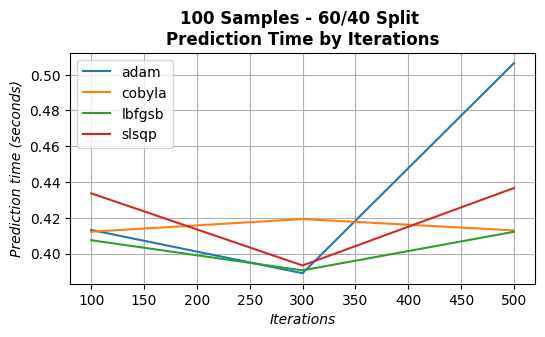

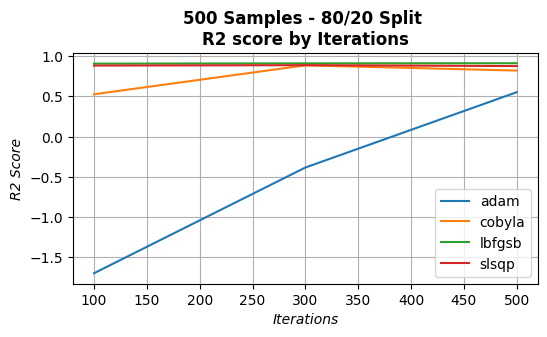

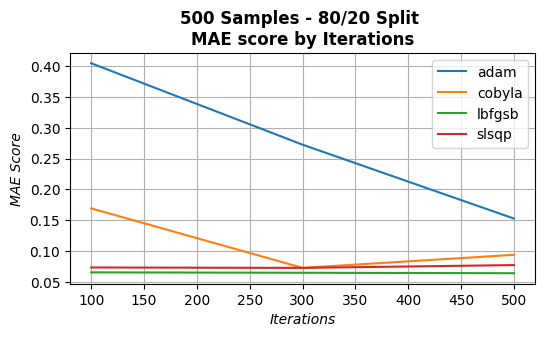

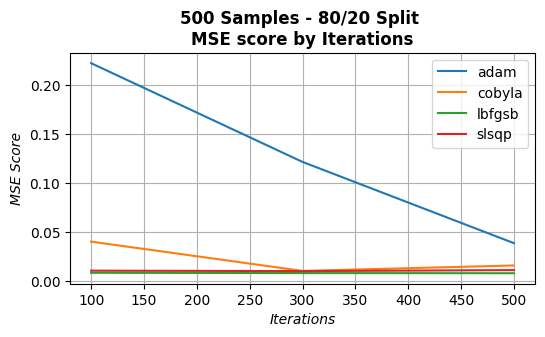

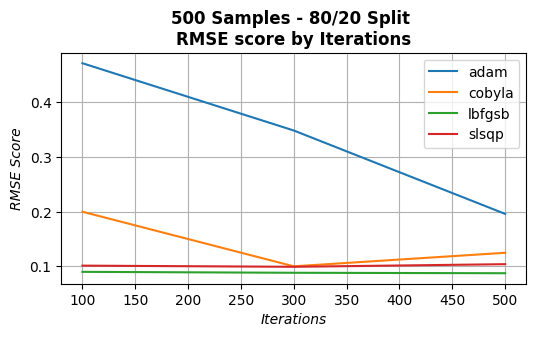

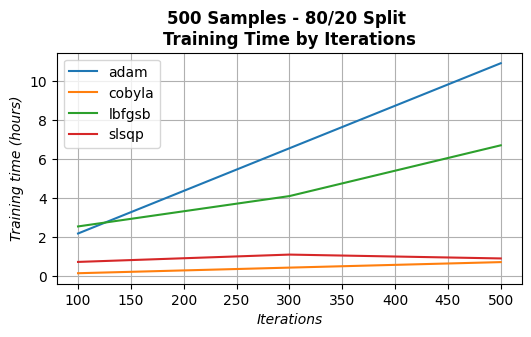

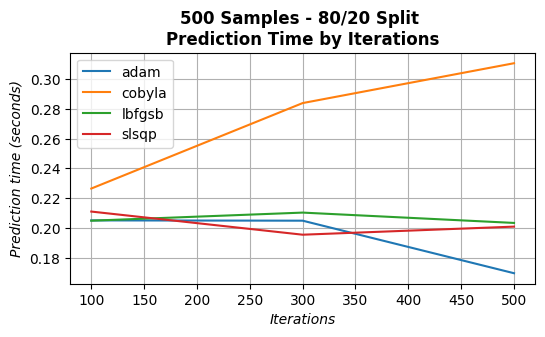

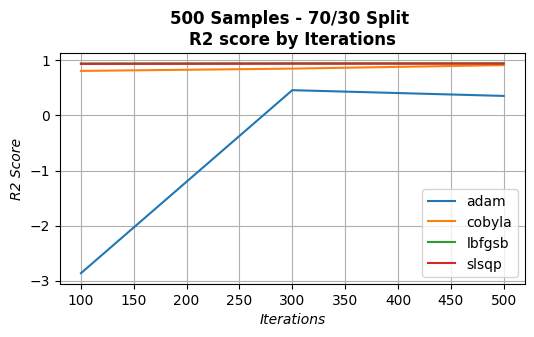

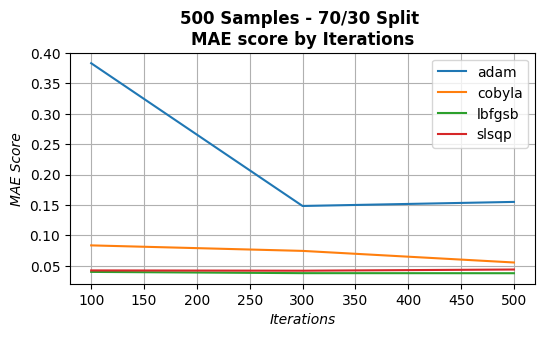

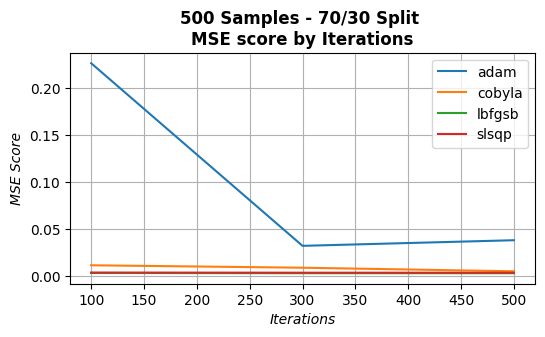

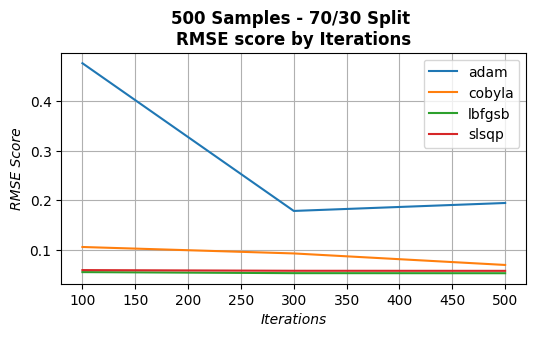

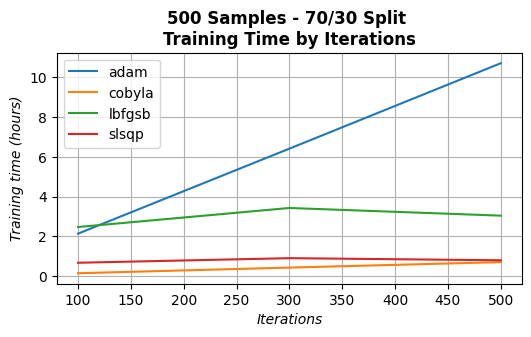

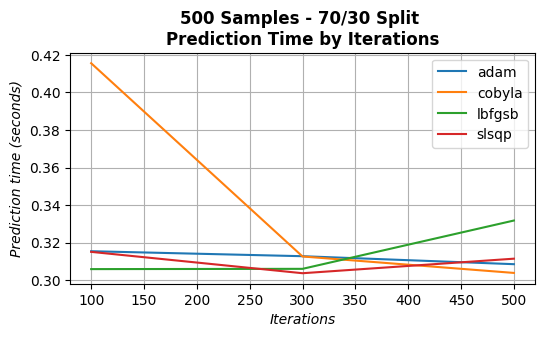

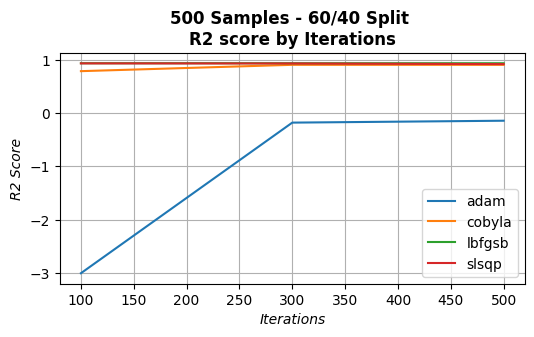

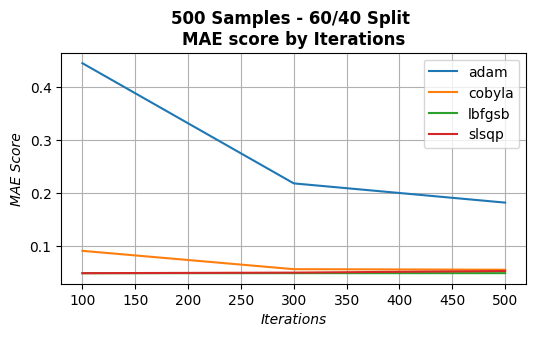

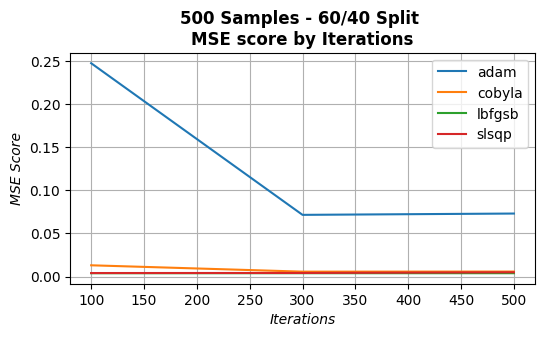

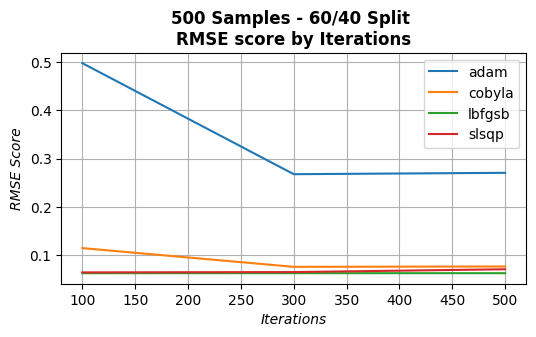

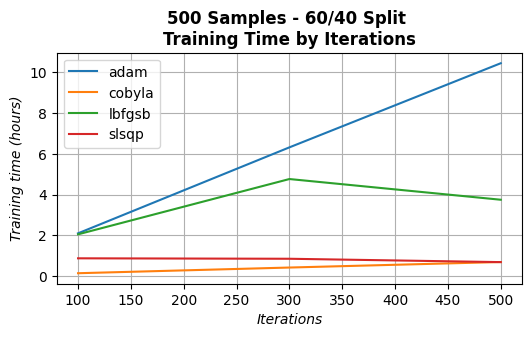

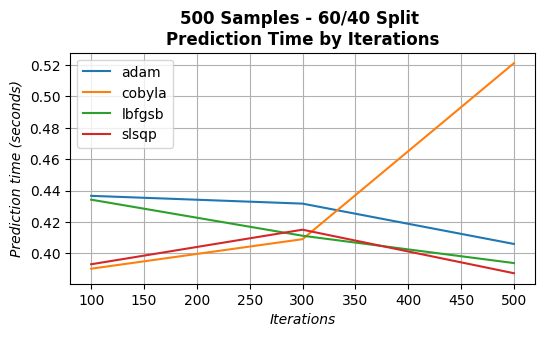

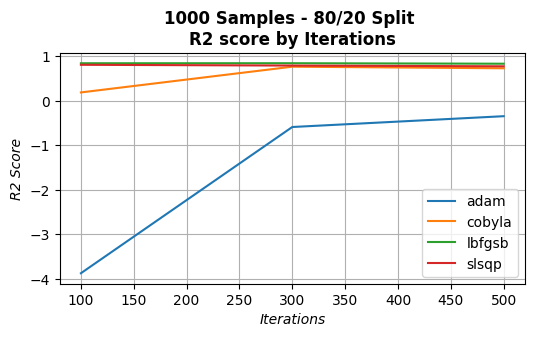

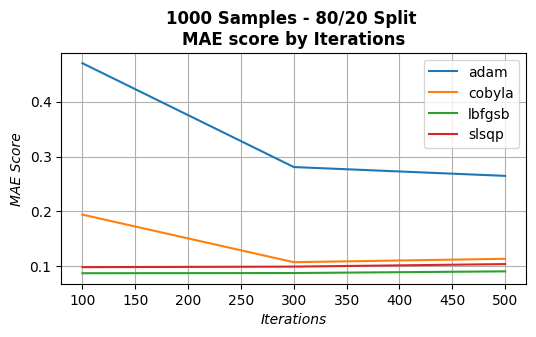

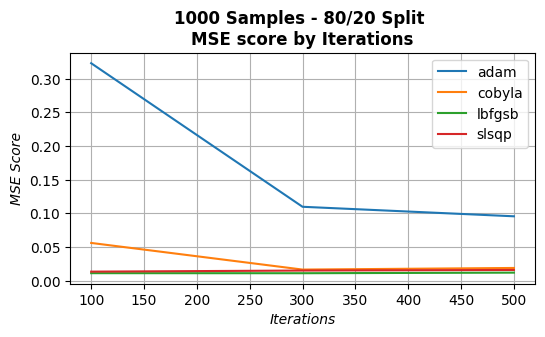

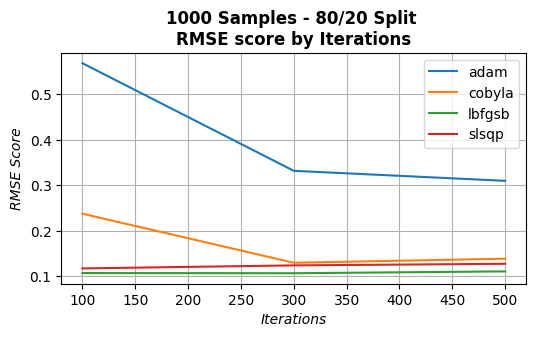

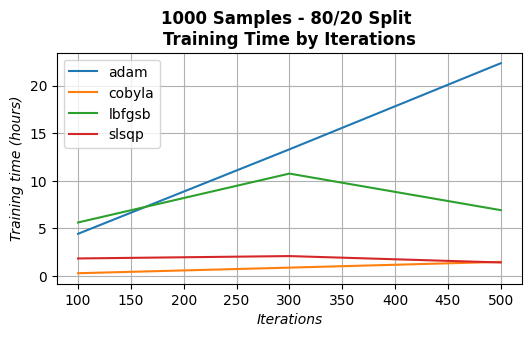

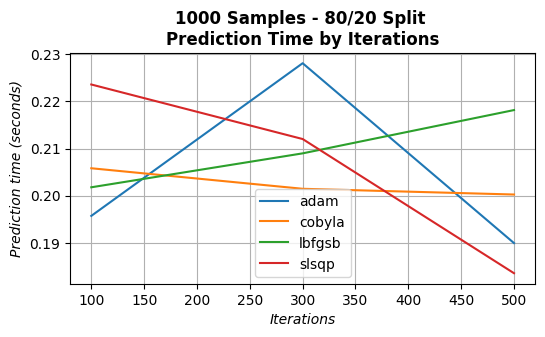

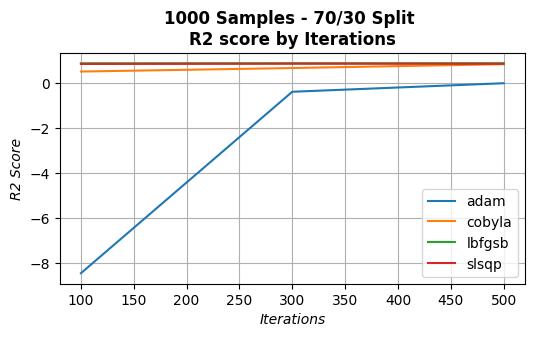

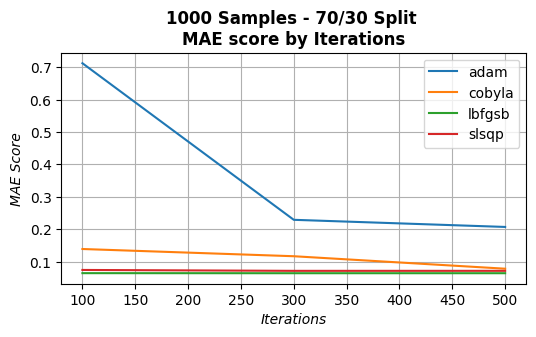

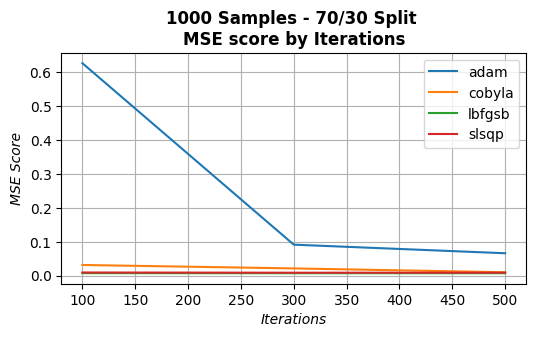

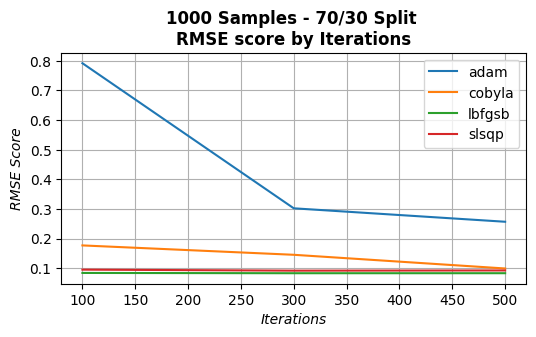

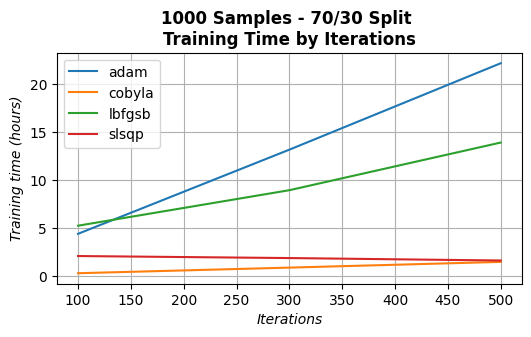

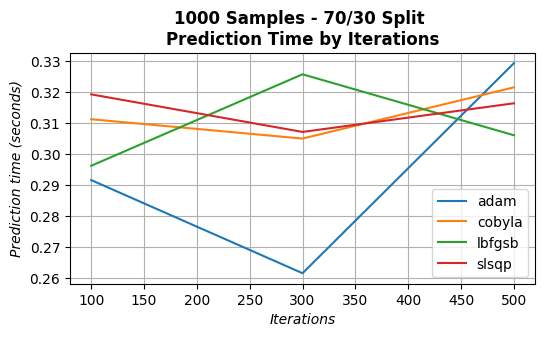

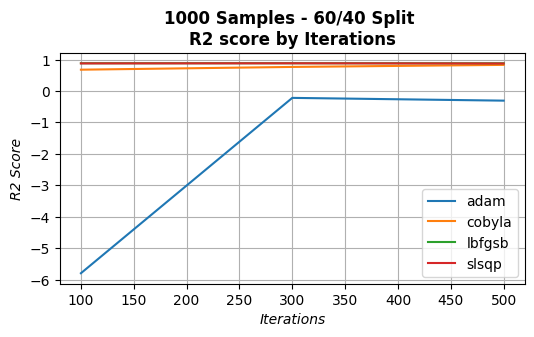

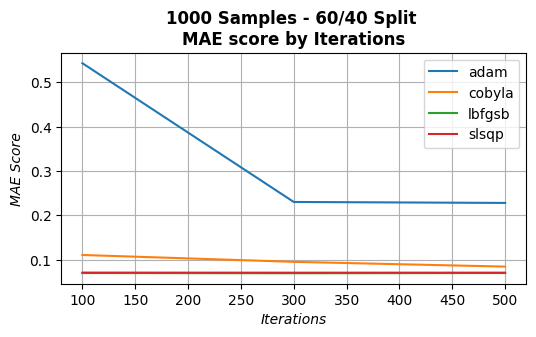

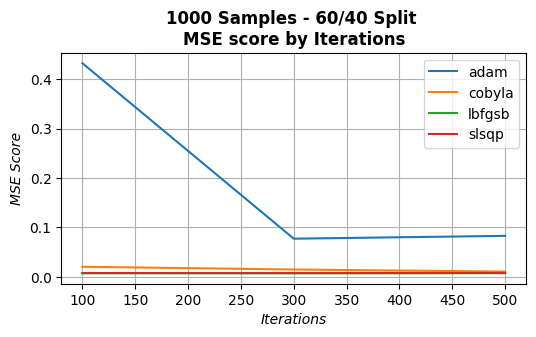

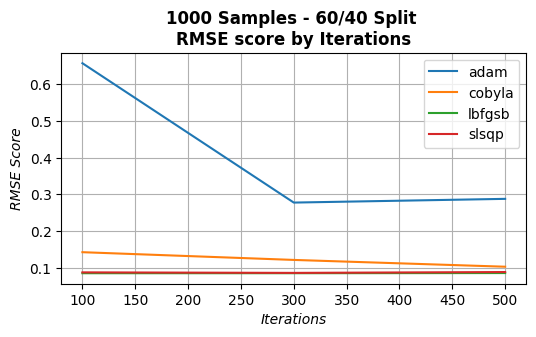

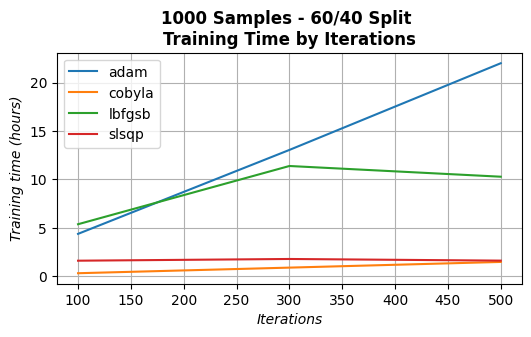

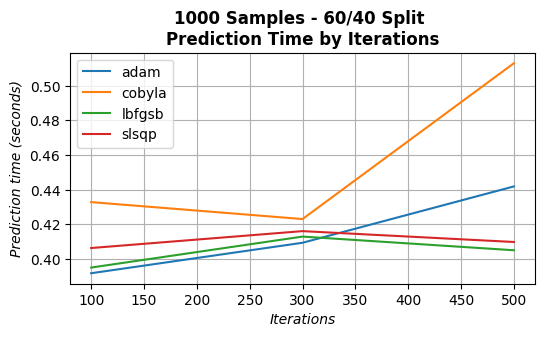

In [11]:
sample_sizes = [100, 500, 1000]
test_sizes = [20, 30, 40]
performance_metrics = ['r2', 'mae', 'mse', 'rmse']
for sample_size in sample_sizes:
    for test_size in test_sizes:
        df_nsamples_by_split = df[(df['n_samples']==sample_size) & (df['test_size'] == test_size)]
        for performance_metric in performance_metrics:
            plot_data(df_nsamples_by_split, 'iterations', performance_metric, f'{sample_size} Samples - {100-test_size}/{test_size} Split \n{performance_metric.upper()} score by Iterations', 'Iterations', f'{performance_metric.upper()} Score')
        plot_data(df_nsamples_by_split, 'iterations', 'training_time', f"{sample_size} Samples - {100-test_size}/{test_size} Split \nTraining Time by Iterations", "Iterations", "Training time (hours)")
        plot_data(df_nsamples_by_split, 'iterations', 'prediction_time', f"{sample_size} Samples - {100-test_size}/{test_size} Split \nPrediction Time by Iterations", "Iterations", "Prediction time (seconds)")

#df_100_samples_by_80_20_split = df[(df['n_samples']==100) & (df['test_size'] == 20)]
#plot_data(df_100_samples_by_80_20_split, 'iterations', 'r2', '100 Samples - 80/20 Split - R2 score by Iterations', 'Iterations', 'R2 Score')